# PW9 - Classification with Support Vector Machines (SVM)

**Team:** Noé Berdoz, Michael Strefeler

## Our starting level

- **Noé Berdoz**: Bachelor in Business Information Technology (Informatique de gestion) at HE-Arc, completed in 2026. This programme focuses on software development and business processes and includes little mathematics, so _TODO: what was new for Noé in this PW_. He had almost no experience in machine learning before this course.
- **Michael Strefeler**: Bachelor in Computer and Communication Systems (ISC) at HEIG-VD, completed in 2025, with a specialisation in data science, so he had already seen some machine learning before this course. _TODO: what was new for Michael in this PW_

## Time spent

| Exercise | Time |
|---|---|
| Ex. 1 a - Training and test sets | 20min |
| Ex. 1 b - SVM with different kernels | 1h |
| Ex. 1 c - Preprocessing and feature extraction (optional) | _TODO_ |
| Ex. 1 d - Analysis of the results | 50min |
| Ex. 2 - Review questions | _TODO_ |
| **Total** | **_TODO_** |

## Bonus request

We would like to apply for the bonus for this PW.

**Why.** _TODO: in our own words, why we should get the bonus, measured against our starting levels_

**What we did as bonus**

- **Ex. 1 a** _TODO_
- **Ex. 1 b** _TODO_
- **Ex. 1 c** _TODO_
- **Ex. 1 d** _TODO_
- **Ex. 2** _TODO_

# Exercice 1 - Digit classification system using different SVM classifiers

## Imports

In [1]:
import gzip
import _pickle as cPickle

# Add your imports here
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from skimage.feature import hog

## Exercise's steps

The objective of this exercise is to build a classification system able to classify the images of handwritten digits (0–9) coming from the MNIST database and using SVM with different types of kernels (linear, polynomial, RBF, ...). For that purpose, you will use the SVM library available in [_Scikit-learn_](http://scikit-learn.org).

### a. Getting the training and test sample sets from the MNIST database

#### a) Load MNIST digit dataset

In [2]:
# Load training, validation (not used in the PW) and test datasets
with gzip.open("mnist.pkl.gz", "rb") as f:
    train_set, valid_set, test_set = cPickle.load(f, encoding="latin1")

# Print the shape of the various datasets
print("Training set:", len(train_set[0]))
print("Validation set:", len(valid_set[0]))
print("Test set:", len(test_set[0]))

Training set: 50000
Validation set: 10000
Test set: 10000


#### b) Visualize (plot) the images of some digits of the MNIST database

                MNIST TRAINING SET                
- Shape of train_set[0]: (50000, 784)
- One image: (784,) values, a 28 x 28 grid
- Pixel values: from 0.0 to 0.9961
- Labels of the first 10 images: [5, 0, 4, 1, 9, 2, 1, 3, 1, 4]


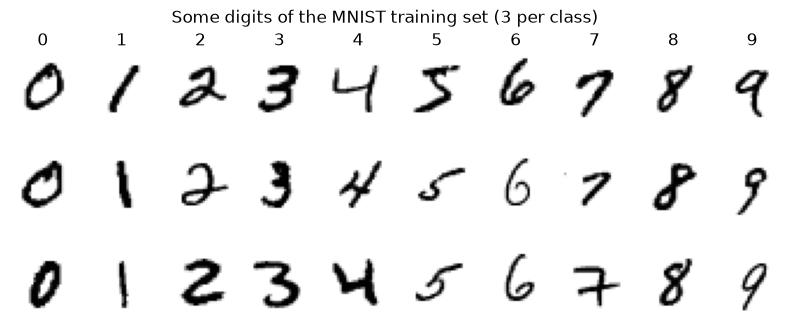

In [3]:
# Your code here
print("=" * 50)
print("MNIST TRAINING SET".center(50))
print("=" * 50)
print("- Shape of train_set[0]:", train_set[0].shape)
print("- One image:", train_set[0][0].shape, "values, a 28 x 28 grid")
print(f"- Pixel values: from {train_set[0].min()} to {train_set[0].max():.4f}")
print("- Labels of the first 10 images:", train_set[1][:10].tolist())
print("=" * 50)

# The first 3 images of each digit
plt.figure(figsize=(10, 3.6))
for k in range(10):
    idx = np.flatnonzero(train_set[1] == k)
    for j in range(3):
        plt.subplot(3, 10, j * 10 + k + 1)
        plt.imshow(train_set[0][idx[j]].reshape(28, 28), cmap="gray_r")
        plt.axis("off")
        if j == 0:
            plt.title(str(k))
plt.suptitle("Some digits of the MNIST training set (3 per class)")
plt.show()

#### c) Build the final training and test sets, which should be balanced

In [4]:
# Your code here
n_train = 200  # images per digit for training
n_test = 100   # images per digit for testing

# The first n_train images of each digit from train_set,
# and the first n_test images of each digit from test_set
train_idx = []
test_idx = []
for k in range(10):
    train_idx.extend(np.flatnonzero(train_set[1] == k)[:n_train])
    test_idx.extend(np.flatnonzero(test_set[1] == k)[:n_test])

X_train = train_set[0][train_idx]
y_train = train_set[1][train_idx]
X_test = test_set[0][test_idx]
y_test = test_set[1][test_idx]

print("=" * 50)
print("BALANCED TRAINING AND TEST SETS".center(50))
print("=" * 50)
print("- X_train:", X_train.shape, " y_train:", y_train.shape)
print("- X_test: ", X_test.shape, " y_test: ", y_test.shape)
print("- Images per digit in X_train:", np.bincount(y_train).tolist())
print("- Images per digit in X_test: ", np.bincount(y_test).tolist())
print("- Images per digit in the full train_set:", np.bincount(train_set[1]).tolist())
print("=" * 50)

         BALANCED TRAINING AND TEST SETS          
- X_train: (2000, 784)  y_train: (2000,)
- X_test:  (1000, 784)  y_test:  (1000,)
- Images per digit in X_train: [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]
- Images per digit in X_test:  [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
- Images per digit in the full train_set: [4932, 5678, 4968, 5101, 4859, 4506, 4951, 5175, 4842, 4988]


Our training set has 2000 images, 200 of each digit, and our test set has 1000 images, 100 of each digit.

We took the first 200 images of each digit from train_set and the first 100 images of each digit from test_set, so no test image is ever used for training. The handout only gives the sizes ("for example 200 per class for training, and 100 for test") and leaves open how to pick the images, so we took the simplest choice, which needs no random seed and gives the same sets at every run.

### b. Classification of digits based on raw pixel values using SVM and different kernels

Create, train and test several SVM classifiers with different kernels (linear, polynomial, RBF, ...). For the training, perform a cross-validation using 10 folds, and test different with several $C$ and kernel parameter values (e.g. for $\gamma$ for RBF kernel) in order to get the best classifier. After the test, display the classification performances and confusion matrix of each SVM classifier (see class _metrics_).

In [7]:
# Your code here
def grid_search(title, model, param_grid):
    # 10-fold cross-validation on the training set only.
    # cv=10 gives the same 10 folds for every model.
    start = time.time()
    search = GridSearchCV(model, param_grid, cv=10, n_jobs=-1)
    search.fit(X_train, y_train)
    duration = time.time() - start

    params = search.cv_results_["params"]
    means = search.cv_results_["mean_test_score"]
    stds = search.cv_results_["std_test_score"]
    print("=" * 50)
    print(f"GRID SEARCH, {title}".center(50))
    print("=" * 50)
    for i in range(len(params)):
        print(f"- {params[i]}: {means[i]:.4f} +/- {stds[i]:.4f}")
    print("-" * 50)
    print("- Best parameters:", search.best_params_)
    print(f"- Best 10-fold CV accuracy: {search.best_score_:.4f}")
    print(f"- Time for the search: {duration:.0f} s on our machine")
    print("=" * 50)
    return search


def plot_heatmap(search, C_list, gamma_list, title):
    means = search.cv_results_["mean_test_score"].reshape(len(C_list), len(gamma_list))
    plt.figure(figsize=(6, 4.5))
    plt.imshow(means, cmap="viridis")
    plt.colorbar(label="mean 10-fold CV accuracy")
    middle = (means.max() + means.min()) / 2
    for i in range(len(C_list)):
        for j in range(len(gamma_list)):
            color = "black" if means[i, j] > middle else "white"
            plt.text(j, i, f"{means[i, j]:.4f}", ha="center", va="center", color=color, fontsize=8)
    plt.xticks(range(len(gamma_list)), gamma_list)
    plt.yticks(range(len(C_list)), C_list)
    plt.xlabel("gamma")
    plt.ylabel("C")
    plt.title(title)
    plt.show()

In [8]:
# Linear Kernel
search_lin = grid_search("LINEAR KERNEL", SVC(kernel="linear"),
                         {"C": [0.001, 0.01, 0.1, 1, 10, 100]})

            GRID SEARCH, LINEAR KERNEL            
- {'C': 0.001}: 0.8375 +/- 0.0332
- {'C': 0.01}: 0.9005 +/- 0.0216
- {'C': 0.1}: 0.8965 +/- 0.0199
- {'C': 1}: 0.8890 +/- 0.0244
- {'C': 10}: 0.8890 +/- 0.0244
- {'C': 100}: 0.8890 +/- 0.0244
--------------------------------------------------
- Best parameters: {'C': 0.01}
- Best 10-fold CV accuracy: 0.9005
- Time for the search: 1 s on our machine


In [11]:
# Polynomial Kernel
# Slide 35: K(xi, xj) = (xi . xj + 1)^d, so gamma=1 and coef0=1 in scikit-learn
search_poly = grid_search("POLYNOMIAL KERNEL", SVC(kernel="poly", gamma=1, coef0=1),
                          {"degree": [2, 3, 4], "C": [0.0001, 0.001, 0.01, 0.1, 1, 10]})

          GRID SEARCH, POLYNOMIAL KERNEL          
- {'C': 0.0001, 'degree': 2}: 0.9110 +/- 0.0215
- {'C': 0.0001, 'degree': 3}: 0.9125 +/- 0.0229
- {'C': 0.0001, 'degree': 4}: 0.8835 +/- 0.0268
- {'C': 0.001, 'degree': 2}: 0.9240 +/- 0.0193
- {'C': 0.001, 'degree': 3}: 0.9125 +/- 0.0229
- {'C': 0.001, 'degree': 4}: 0.8835 +/- 0.0268
- {'C': 0.01, 'degree': 2}: 0.9225 +/- 0.0166
- {'C': 0.01, 'degree': 3}: 0.9125 +/- 0.0229
- {'C': 0.01, 'degree': 4}: 0.8835 +/- 0.0268
- {'C': 0.1, 'degree': 2}: 0.9225 +/- 0.0166
- {'C': 0.1, 'degree': 3}: 0.9125 +/- 0.0229
- {'C': 0.1, 'degree': 4}: 0.8835 +/- 0.0268
- {'C': 1, 'degree': 2}: 0.9225 +/- 0.0166
- {'C': 1, 'degree': 3}: 0.9125 +/- 0.0229
- {'C': 1, 'degree': 4}: 0.8835 +/- 0.0268
- {'C': 10, 'degree': 2}: 0.9225 +/- 0.0166
- {'C': 10, 'degree': 3}: 0.9125 +/- 0.0229
- {'C': 10, 'degree': 4}: 0.8835 +/- 0.0268
--------------------------------------------------
- Best parameters: {'C': 0.001, 'degree': 2}
- Best 10-fold CV accuracy: 0.9240

       GRID SEARCH, RBF KERNEL, COARSE GRID       
- {'C': 0.1, 'gamma': 0.0001}: 0.6905 +/- 0.0405
- {'C': 0.1, 'gamma': 0.001}: 0.7065 +/- 0.0359
- {'C': 0.1, 'gamma': 0.01}: 0.8600 +/- 0.0289
- {'C': 0.1, 'gamma': 0.1}: 0.3290 +/- 0.0529
- {'C': 0.1, 'gamma': 1}: 0.1045 +/- 0.0035
- {'C': 1, 'gamma': 0.0001}: 0.6980 +/- 0.0401
- {'C': 1, 'gamma': 0.001}: 0.8725 +/- 0.0263
- {'C': 1, 'gamma': 0.01}: 0.9230 +/- 0.0166
- {'C': 1, 'gamma': 0.1}: 0.7695 +/- 0.0547
- {'C': 1, 'gamma': 1}: 0.1410 +/- 0.0073
- {'C': 10, 'gamma': 0.0001}: 0.8695 +/- 0.0270
- {'C': 10, 'gamma': 0.001}: 0.9055 +/- 0.0224
- {'C': 10, 'gamma': 0.01}: 0.9260 +/- 0.0143
- {'C': 10, 'gamma': 0.1}: 0.7870 +/- 0.0543
- {'C': 10, 'gamma': 1}: 0.1490 +/- 0.0094
- {'C': 100, 'gamma': 0.0001}: 0.9020 +/- 0.0243
- {'C': 100, 'gamma': 0.001}: 0.8995 +/- 0.0199
- {'C': 100, 'gamma': 0.01}: 0.9260 +/- 0.0143
- {'C': 100, 'gamma': 0.1}: 0.7870 +/- 0.0543
- {'C': 100, 'gamma': 1}: 0.1490 +/- 0.0094
- {'C': 1000, 'gamma': 0.000

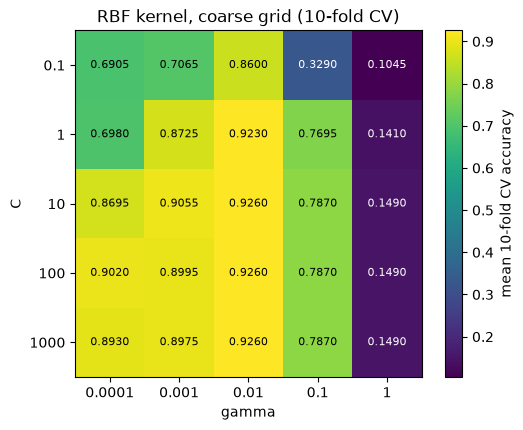

In [13]:
# Gaussian / RBF Kernel (first: a coarse grid, with powers of 10)
C_coarse = [0.1, 1, 10, 100, 1000]
gamma_coarse = [0.0001, 0.001, 0.01, 0.1, 1]
search_rbf_coarse = grid_search("RBF KERNEL, COARSE GRID", SVC(kernel="rbf"),
                                {"C": C_coarse, "gamma": gamma_coarse})
plot_heatmap(search_rbf_coarse, C_coarse, gamma_coarse, "RBF kernel, coarse grid (10-fold CV)")

        GRID SEARCH, RBF KERNEL, FINE GRID        
- {'C': 0.5, 'gamma': 0.005}: 0.9000 +/- 0.0221
- {'C': 0.5, 'gamma': 0.01}: 0.9135 +/- 0.0219
- {'C': 0.5, 'gamma': 0.02}: 0.9265 +/- 0.0178
- {'C': 0.5, 'gamma': 0.03}: 0.9230 +/- 0.0206
- {'C': 0.5, 'gamma': 0.04}: 0.9125 +/- 0.0211
- {'C': 0.5, 'gamma': 0.05}: 0.8955 +/- 0.0244
- {'C': 1, 'gamma': 0.005}: 0.9135 +/- 0.0184
- {'C': 1, 'gamma': 0.01}: 0.9230 +/- 0.0166
- {'C': 1, 'gamma': 0.02}: 0.9320 +/- 0.0165
- {'C': 1, 'gamma': 0.03}: 0.9365 +/- 0.0148
- {'C': 1, 'gamma': 0.04}: 0.9315 +/- 0.0164
- {'C': 1, 'gamma': 0.05}: 0.9230 +/- 0.0196
- {'C': 2, 'gamma': 0.005}: 0.9165 +/- 0.0191
- {'C': 2, 'gamma': 0.01}: 0.9285 +/- 0.0166
- {'C': 2, 'gamma': 0.02}: 0.9340 +/- 0.0150
- {'C': 2, 'gamma': 0.03}: 0.9380 +/- 0.0155
- {'C': 2, 'gamma': 0.04}: 0.9330 +/- 0.0166
- {'C': 2, 'gamma': 0.05}: 0.9245 +/- 0.0198
- {'C': 5, 'gamma': 0.005}: 0.9230 +/- 0.0163
- {'C': 5, 'gamma': 0.01}: 0.9275 +/- 0.0136
- {'C': 5, 'gamma': 0.02}: 0.9335

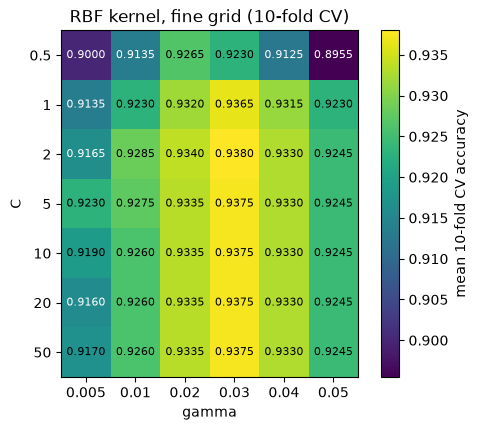

- Cross-check with cross_val_score: 0.9380
- C = 1: 1501 support vectors, 245 at the bound C, training accuracy 0.9985
- C = 2: 1506 support vectors, 25 at the bound C, training accuracy 1.0000
- C = 5: 1507 support vectors, 0 at the bound C, training accuracy 1.0000
- C = 10: 1507 support vectors, 0 at the bound C, training accuracy 1.0000
- C = 50: 1507 support vectors, 0 at the bound C, training accuracy 1.0000


In [14]:
# Gaussian / RBF Kernel (second: a finer grid around the best cell of the coarse grid (C=10, gamma=0.01))
C_fine = [0.5, 1, 2, 5, 10, 20, 50]
gamma_fine = [0.005, 0.01, 0.02, 0.03, 0.04, 0.05]
search_rbf = grid_search("RBF KERNEL, FINE GRID", SVC(kernel="rbf"),
                         {"C": C_fine, "gamma": gamma_fine})
plot_heatmap(search_rbf, C_fine, gamma_fine, "RBF kernel, fine grid (10-fold CV)")

# Cross-check: the same 10 folds, computed again with cross_val_score
check = cross_val_score(SVC(kernel="rbf", C=2, gamma=0.03), X_train, y_train, cv=10)
print(f"- Cross-check with cross_val_score: {check.mean():.4f}")

# Why C stops mattering: how many support vectors have their alpha at the bound C?
# Only those can be inside the margin. With 0 of them, the hinge loss is 0 for every training image.
for C in [1, 2, 5, 10, 50]:
    model = SVC(kernel="rbf", C=C, gamma=0.03).fit(X_train, y_train)
    alphas = np.max(np.abs(model.dual_coef_), axis=0)
    at_bound = int(np.sum(alphas >= C - 1e-6))
    train_acc = np.mean(model.predict(X_train) == y_train)
    print(f"- C = {C}: {int(model.n_support_.sum())} support vectors, {at_bound} at the bound C, training accuracy {train_acc:.4f}")

             TEST SET, LINEAR KERNEL              
- Parameters: {'C': 0.01}
              precision    recall  f1-score   support

           0      0.960     0.950     0.955       100
           1      0.961     0.990     0.975       100
           2      0.825     0.850     0.837       100
           3      0.914     0.740     0.818       100
           4      0.873     0.890     0.881       100
           5      0.765     0.880     0.819       100
           6      0.935     0.870     0.902       100
           7      0.851     0.860     0.856       100
           8      0.870     0.800     0.833       100
           9      0.820     0.910     0.863       100

    accuracy                          0.874      1000
   macro avg      0.877     0.874     0.874      1000
weighted avg      0.877     0.874     0.874      1000

- Test accuracy: 0.874 (874 / 1000)
- Cross-check, trace / sum of the confusion matrix: 0.874


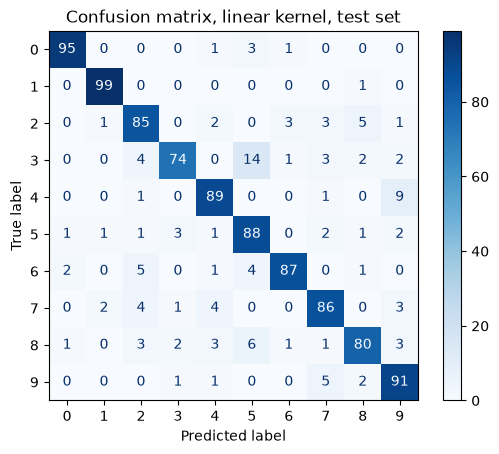

           TEST SET, POLYNOMIAL KERNEL            
- Parameters: {'C': 0.001, 'degree': 2}
              precision    recall  f1-score   support

           0      0.951     0.980     0.966       100
           1      0.962     1.000     0.980       100
           2      0.894     0.930     0.912       100
           3      0.920     0.800     0.856       100
           4      0.883     0.910     0.897       100
           5      0.858     0.910     0.883       100
           6      0.948     0.920     0.934       100
           7      0.892     0.910     0.901       100
           8      0.914     0.850     0.881       100
           9      0.911     0.920     0.915       100

    accuracy                          0.913      1000
   macro avg      0.913     0.913     0.912      1000
weighted avg      0.913     0.913     0.912      1000

- Test accuracy: 0.913 (913 / 1000)
- Cross-check, trace / sum of the confusion matrix: 0.913


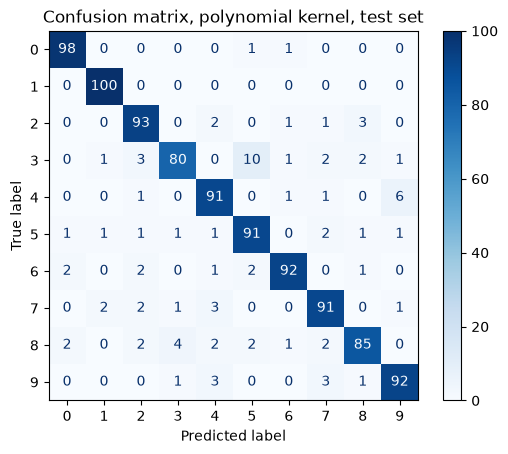

               TEST SET, RBF KERNEL               
- Parameters: {'C': 2, 'gamma': 0.03}
              precision    recall  f1-score   support

           0      0.961     0.980     0.970       100
           1      0.990     1.000     0.995       100
           2      0.920     0.920     0.920       100
           3      0.955     0.850     0.899       100
           4      0.909     0.900     0.905       100
           5      0.879     0.940     0.908       100
           6      0.958     0.920     0.939       100
           7      0.919     0.910     0.915       100
           8      0.890     0.890     0.890       100
           9      0.879     0.940     0.908       100

    accuracy                          0.925      1000
   macro avg      0.926     0.925     0.925      1000
weighted avg      0.926     0.925     0.925      1000

- Test accuracy: 0.925 (925 / 1000)
- Cross-check, trace / sum of the confusion matrix: 0.925


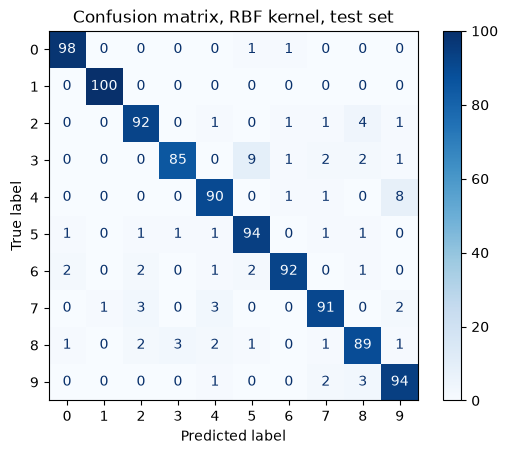

In [15]:
searches = [search_lin, search_poly, search_rbf]
names = ["linear", "polynomial", "RBF"]
test_acc = []
for i in range(3):
    model = searches[i].best_estimator_
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    test_acc.append(np.mean(y_pred == y_test))

    print("=" * 50)
    print(f"TEST SET, {names[i].upper()} KERNEL".center(50))
    print("=" * 50)
    print("- Parameters:", searches[i].best_params_)
    print(classification_report(y_test, y_pred, digits=3))
    print(f"- Test accuracy: {test_acc[i]:.3f} ({np.sum(y_pred == y_test)} / {len(y_test)})")
    print(f"- Cross-check, trace / sum of the confusion matrix: {np.trace(cm) / np.sum(cm):.3f}")
    print("=" * 50)

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
    plt.title(f"Confusion matrix, {names[i]} kernel, test set")
    plt.show()

In [16]:
print("=" * 62)
print("SUMMARY, RAW PIXELS".center(62))
print("=" * 62)
print(f"{'kernel':<12}{'best parameters':<26}{'CV':>8}{'test':>8}{'SV':>8}")
print("-" * 62)
for i in range(3):
    params = str(searches[i].best_params_).replace("'", "")
    n_sv = searches[i].best_estimator_.n_support_.sum()
    print(f"{names[i]:<12}{params:<26}{searches[i].best_score_:>8.4f}{test_acc[i]:>8.3f}{n_sv:>8}")
print("=" * 62)

                     SUMMARY, RAW PIXELS                      
kernel      best parameters                 CV    test      SV
--------------------------------------------------------------
linear      {C: 0.01}                   0.9005   0.874    1162
polynomial  {C: 0.001, degree: 2}       0.9240   0.913     919
RBF         {C: 2, gamma: 0.03}         0.9380   0.925    1506


In [17]:
# BONUS: the RBF kernel K = exp(-gamma * ||x - x'||^2), computed by hand
def rbf_by_hand(A, B, gamma):
    A = A.astype(float)
    B = B.astype(float)
    K = np.zeros((len(A), len(B)))
    for i in range(len(A)):
        K[i] = np.exp(-gamma * np.sum((B - A[i]) ** 2, axis=1))
    return K

K_train = rbf_by_hand(X_train, X_train, 0.03)  # 2000 x 2000
K_test = rbf_by_hand(X_test, X_train, 0.03)    # 1000 x 2000, test against training
model_k = SVC(kernel="precomputed", C=2).fit(K_train, y_train)
y_pred_k = model_k.predict(K_test)

print("=" * 50)
print("RBF KERNEL BY HAND".center(50))
print("=" * 50)
print("- K_train:", K_train.shape, " K_test:", K_test.shape)
print(f"- K between training images 600 and 1000: {K_train[600, 1000]:.4f}")
print(f"- Test accuracy with the kernel by hand: {np.mean(y_pred_k == y_test):.3f}")
print("- Same 1000 predictions as SVC(kernel='rbf'):", np.all(y_pred_k == search_rbf.predict(X_test)))
print("=" * 50)

                RBF KERNEL BY HAND                
- K_train: (2000, 2000)  K_test: (1000, 2000)
- K between training images 600 and 1000: 0.1158
- Test accuracy with the kernel by hand: 0.925
- Same 1000 predictions as SVC(kernel='rbf'): True


The RBF kernel gives the best classifier: 0.9380 in 10-fold cross-validation and 0.925 on the test set, with C = 2 and $\gamma = 0.03$.

The polynomial kernel $(x \cdot x' + 1)^d$, comes second with 0.9240 and 0.913 ($d = 2$, C = 0.001). The linear kernel is last with 0.9005 and 0.874 (C = 0.01).

We chose every parameter with GridSearchCV and cv=10 on the 2000 training images, so the three kernels saw the same 10 folds, and we used the test set once per kernel. The three kernels make the same two largest mistakes: 3 read as 5 (14, 10 and 9 test images for the linear, polynomial and RBF kernels) and 4 read as 9 (9, 6 and 8 images).

### c. (Optional) Impact of preprocessing and feature extraction

Analyse the impact of the classification performances using the following preprocessing and feature extraction steps:

#### a) Preprocessing step: convert images to binary (i.e. black and white) representations 

In [6]:
# Your code here

#### b) Feature extraction steps:
* Horizontal and vertical projections (i.e. compute the sum of grey pixel values along the the X and Y-axis)
* Local binary patterns
* Any other usable image features that you may have found

In [7]:
# Your code here

### d. Analysis of the results

Analyse the results obtained with the best SVM classifier.

          BEST SVM: RBF, C=2, gamma=0.03          
digit   recall   precision
  0     0.98      0.96
  1     1.00      0.99
  2     0.92      0.92
  3     0.85      0.96
  4     0.90      0.91
  5     0.94      0.88
  6     0.92      0.96
  7     0.91      0.92
  8     0.89      0.89
  9     0.94      0.88
--------------------------------------------------
Largest confusions (true -> predicted):
- 3 -> 5: 9 test images
- 4 -> 9: 8 test images
- 2 -> 8: 4 test images
- 9 -> 8: 3 test images
- 8 -> 3: 3 test images
- Total of mistakes: 75 (cross-check: 75)
--------------------------------------------------
Closest mean images (squared distance):
- 4 and 9: 8.43
- 3 and 5: 9.13
- 7 and 9: 9.28
- 5 and 8: 12.13
- 5 and 9: 14.82
- the farthest pair, 0 and 1: 59.48


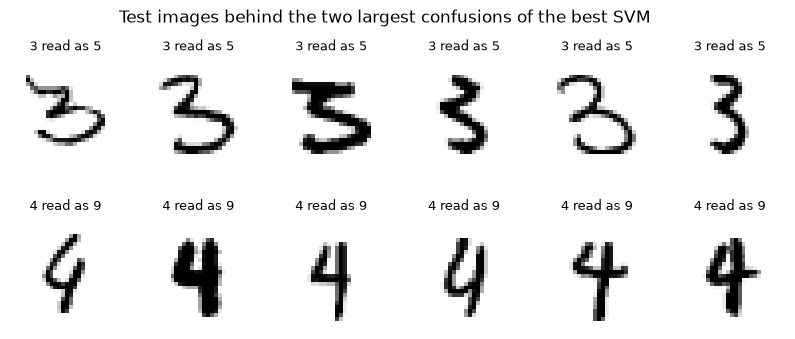

In [18]:
best = search_rbf.best_estimator_
y_pred = best.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
recall = np.diag(cm) / np.sum(cm, axis=1)
precision = np.diag(cm) / np.sum(cm, axis=0)

# Every mistake of the confusion matrix, the largest first
mistakes = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            mistakes.append([cm[i, j], i, j])
mistakes.sort(reverse=True)

print("=" * 50)
print(f"BEST SVM: RBF, C={search_rbf.best_params_['C']}, gamma={search_rbf.best_params_['gamma']}".center(50))
print("=" * 50)
print("digit   recall   precision")
for k in range(10):
    print(f"  {k}     {recall[k]:.2f}      {precision[k]:.2f}")
print("-" * 50)
print("Largest confusions (true -> predicted):")
for m in range(5):
    print(f"- {mistakes[m][1]} -> {mistakes[m][2]}: {mistakes[m][0]} test images")
print(f"- Total of mistakes: {len(y_test) - np.trace(cm)} (cross-check: {np.sum(y_pred != y_test)})")
print("-" * 50)

# How close are two digits in pixel space? Squared distance between their mean training images
means = []
for k in range(10):
    means.append(X_train[y_train == k].mean(axis=0))
mean_dist = []
for i in range(10):
    for j in range(i + 1, 10):
        mean_dist.append([np.sum((means[i] - means[j]) ** 2), i, j])
mean_dist.sort()
print("Closest mean images (squared distance):")
for m in range(5):
    print(f"- {mean_dist[m][1]} and {mean_dist[m][2]}: {mean_dist[m][0]:.2f}")
print(f"- the farthest pair, {mean_dist[-1][1]} and {mean_dist[-1][2]}: {mean_dist[-1][0]:.2f}")
print("=" * 50)

# The test images behind the two largest confusions
plt.figure(figsize=(10, 3.8))
for m in range(2):
    true_digit = mistakes[m][1]
    pred_digit = mistakes[m][2]
    wrong = np.flatnonzero((y_test == true_digit) & (y_pred == pred_digit))
    for j in range(min(6, len(wrong))):
        plt.subplot(2, 6, m * 6 + j + 1)
        plt.imshow(X_test[wrong[j]].reshape(28, 28), cmap="gray_r")
        plt.title(f"{true_digit} read as {pred_digit}", fontsize=9)
        plt.axis("off")
plt.suptitle("Test images behind the two largest confusions of the best SVM")
plt.show()

a) Which kernel and parameters were used?

Our best SVM on raw pixels uses the RBF kernel $K(x, x') = \exp(-\gamma \|x - x'\|^2)$ with C = 2 and $\gamma = 0.03$ (CV 0.9380, test 0.925).

We found it using a two-step 10-fold grid search, starting with a coarse grid of powers of 10 (best C = 10, $\gamma = 0.01$, CV 0.9260), and then refining around those values.

From C = 5 on, no support vector has its weight at the bound C, so no training image is inside the margin, the hinge loss is 0 and C stops changing anything (CV 0.9375). C = 2 still has 25 support vectors at the bound, a slightly softer margin, and wins by one image out of 2000.

With the HOG features of 1 c, the best SVM is also an RBF kernel, with C = 1 and $\gamma = 0.3312$ (CV 0.9615, test 0.951).

b) Which digit classes are the best/worse recognized against which? Why?

The best recognised digits are 1 (recall 1.00) and 0 (recall 0.98), and the worst is 3 (recall 0.85), which is mostly read as 5.

The largest mistakes are 3 read as 5 (9 test images), 4 read as 9 (8) and 2 read as 8 (4), which also lower the precision of 5 and 9 to 0.88.

These digits are very close in pixel space. The squared distance between their mean training images is 8.43 for 4 and 9 and 9.13 for 3 and 5, which are the two smallest values out of all 45 pairs (compared to 59.48 for 0 and 1). A 3 and a 5 share their lower curve, and a 4 with a closed top looks like a 9.

The same two pairs are the largest mistakes of the linear and polynomial kernels and of the HOG model (4 images each), so they come from the digits, not from the kernel.

c) What is the impact of the sizes of the training and test sets on the classification performance?

Increasing the training set size improves test accuracy with diminishing returns, moving from weak performance with very few images to high accuracy with several thousand and beyond, at the cost of much longer fitting times.

Changing the test set size does not change the model or its true classification performance, only the precision of the evaluation. A smaller test set produces much wider variance in accuracy across random samples, so small score differences on a limited test set can simply reflect sampling noise rather than a real difference between models.

We added bonus code below to illustrate these observations.

     TRAINING SET SIZE (RBF, C=2, gamma=0.03)     
per digit   total   test accuracy   fit time   support vectors
       10     100      0.616         0.00 s        100
       20     200      0.726         0.01 s        197
       50     500      0.861         0.04 s        461
      100    1000      0.889         0.13 s        854
      200    2000      0.925         0.40 s       1506
      500    5000      0.949         1.34 s       2999
     1000   10000      0.958         4.02 s       4896
     2000   20000      0.970        11.83 s       7917
     4000   40000      0.981        34.24 s      12517


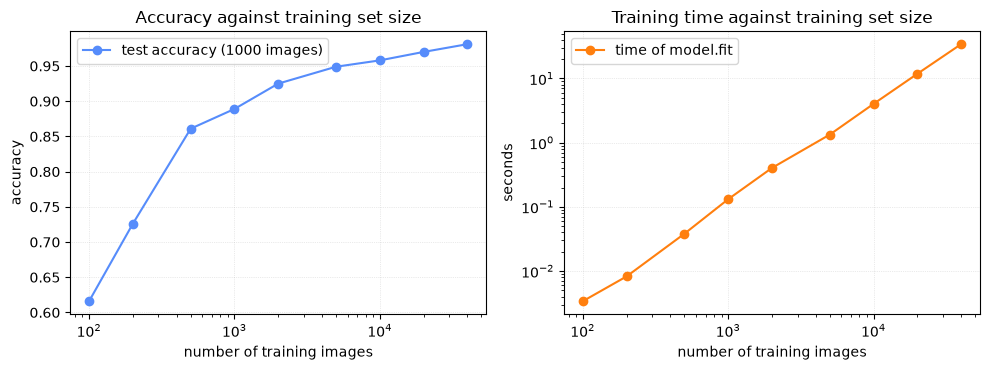

In [19]:
# Same parameters, same 1000 test images, more and more training images
sizes = [10, 20, 50, 100, 200, 500, 1000, 2000, 4000]  # images per digit
n_images = []
acc_size = []
fit_time = []
n_sv = []
for i in range(len(sizes)):
    idx = []
    for k in range(10):
        idx.extend(np.flatnonzero(train_set[1] == k)[:sizes[i]])
    n_images.append(len(idx))
    model = SVC(kernel="rbf", C=2, gamma=0.03)
    start = time.time()
    model.fit(train_set[0][idx], train_set[1][idx])
    fit_time.append(time.time() - start)
    acc_size.append(np.mean(model.predict(X_test) == y_test))
    n_sv.append(model.n_support_.sum())

print("=" * 50)
print("TRAINING SET SIZE (RBF, C=2, gamma=0.03)".center(50))
print("=" * 50)
print("per digit   total   test accuracy   fit time   support vectors")
for i in range(len(sizes)):
    print(f"{sizes[i]:>9} {n_images[i]:>7}      {acc_size[i]:.3f}       {fit_time[i]:>6.2f} s   {n_sv[i]:>8}")
print("=" * 50)

plt.figure(figsize=(10, 3.8))
plt.subplot(1, 2, 1)
plt.plot(n_images, acc_size, "o-", label="test accuracy (1000 images)")
plt.xscale("log")
plt.xlabel("number of training images")
plt.ylabel("accuracy")
plt.title("Accuracy against training set size")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.5)
plt.subplot(1, 2, 2)
plt.plot(n_images, fit_time, "o-", color="tab:orange", label="time of model.fit")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("number of training images")
plt.ylabel("seconds")
plt.title("Training time against training set size")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

   TEST SET SIZE (1000 random balanced draws per size)    
- Accuracy on the 10000 images of test_set: 0.9399
per digit  total   mean    std    min    max   sqrt(p(1-p)/n)
        5     50  0.941  0.032  0.780  1.000  0.034
       10    100  0.939  0.024  0.830  1.000  0.024
       20    200  0.940  0.017  0.865  0.980  0.017
       50    500  0.940  0.010  0.896  0.978  0.011
      100   1000  0.940  0.007  0.917  0.966  0.008
      200   2000  0.939  0.005  0.925  0.953  0.005


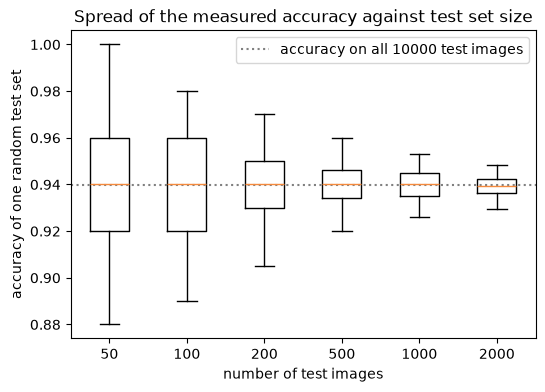

In [21]:
# The best model predicts the 10000 images of test_set once
correct_all = best.predict(test_set[0]) == test_set[1]
p = np.mean(correct_all)

# Draw 1000 balanced test sets of each size and measure the spread of the accuracy
rng = np.random.default_rng(0)
class_idx = []
for k in range(10):
    class_idx.append(np.flatnonzero(test_set[1] == k))
test_sizes = [5, 10, 20, 50, 100, 200]  # images per digit
n_test_images = []
draws = []
for i in range(len(test_sizes)):
    accs = []
    for r in range(1000):
        idx = []
        for k in range(10):
            idx.extend(rng.choice(class_idx[k], test_sizes[i], replace=False))
        accs.append(np.mean(correct_all[idx]))
    draws.append(accs)
    n_test_images.append(test_sizes[i] * 10)

print("=" * 58)
print("TEST SET SIZE (1000 random balanced draws per size)".center(58))
print("=" * 58)
print(f"- Accuracy on the 10000 images of test_set: {p:.4f}")
print("per digit  total   mean    std    min    max   sqrt(p(1-p)/n)")
for i in range(len(test_sizes)):
    n = n_test_images[i]
    a = draws[i]
    print(f"{test_sizes[i]:>9} {n:>6}  {np.mean(a):.3f}  {np.std(a):.3f}  {np.min(a):.3f}  {np.max(a):.3f}  {np.sqrt(p * (1 - p) / n):.3f}")
print("=" * 58)

plt.figure(figsize=(6, 4))
plt.boxplot(draws, whis=(2.5, 97.5), showfliers=False)
plt.xticks(range(1, len(test_sizes) + 1), n_test_images)
plt.axhline(p, color="gray", linestyle=":", label="accuracy on all 10000 test images")
plt.xlabel("number of test images")
plt.ylabel("accuracy of one random test set")
plt.title("Spread of the measured accuracy against test set size")
plt.legend()
plt.show()